In [2]:
import mapof.marriages as mapof
import pandas
from ast import literal_eval
import numpy as np

In [3]:
reverse_euclid = pandas.read_csv('reverse_euclidean_gain.csv')
mallows = pandas.read_csv('mallows_gain.csv')
mallows_MD = pandas.read_csv('mallows_MD_gain.csv')
mallows_MA = pandas.read_csv('mallows_MA_gain.csv')
mallows_euclidean = pandas.read_csv('mallows_euclidean_gain.csv')
expectations_euclidean = pandas.read_csv('expectations_euclidean_gain.csv')

In [4]:
future_votes_rev_euclidean = reverse_euclid['preferences'].apply(literal_eval)
rev_euclid_feature = reverse_euclid['avg_self_benefit']

future_votes_mallows = mallows['preferences'].apply(literal_eval)
mallows_feature = mallows['avg_self_benefit']

future_votes_mallows_MD = mallows_MD['preferences'].apply(literal_eval)
mallows_MD_feature = mallows_MD['avg_self_benefit']

future_votes_mallows_MA = mallows_MA['preferences'].apply(literal_eval)
mallows_MA_feature = mallows_MA['avg_self_benefit']

future_votes_mallows_euclidean = mallows_euclidean['preferences'].apply(literal_eval)
mallows_euclidean_feature = mallows_euclidean['avg_self_benefit']

future_votes_expectations_euclidean = expectations_euclidean['preferences'].apply(literal_eval)
expectations_euclidean_feature = expectations_euclidean['avg_self_benefit']

In [329]:
rev_euclid_feature, future_votes_rev_euclidean = zip(*[
    (fval, fv)
    for fval, fv in zip(rev_euclid_feature, future_votes_rev_euclidean)
    if fval != 0 and fval <= 1.1
])
rev_euclid_feature = list(rev_euclid_feature)
future_votes_rev_euclidean = list(future_votes_rev_euclidean)

mallows_feature, future_votes_mallows = zip(*[
    (fval, fv)
    for fval, fv in zip(mallows_feature, future_votes_mallows)
    if fval != 0 and fval <= 1.1
])
mallows_feature = list(mallows_feature)
future_votes_mallows = list(future_votes_mallows)

mallows_MD_feature, future_votes_mallows_MD = zip(*[
    (fval, fv)
    for fval, fv in zip(mallows_MD_feature, future_votes_mallows_MD)
    if fval != 0 and fval <= 1.1
])
mallows_MD_feature = list(mallows_MD_feature)
future_votes_mallows_MD = list(future_votes_mallows_MD)

mallows_MA_feature, future_votes_mallows_MA = zip(*[
    (fval, fv)
    for fval, fv in zip(mallows_MA_feature, future_votes_mallows_MA)
    if fval != 0 and fval <= 1.1
])
mallows_MA_feature = list(mallows_MA_feature)
future_votes_mallows_MA = list(future_votes_mallows_MA)

mallows_euclidean_feature, future_votes_mallows_euclidean = zip(*[
    (fval, fv)
    for fval, fv in zip(mallows_euclidean_feature, future_votes_mallows_euclidean)
    if fval != 0 and fval <= 1.1
])
mallows_euclidean_feature = list(mallows_euclidean_feature)
future_votes_mallows_euclidean = list(future_votes_mallows_euclidean)

expectations_euclidean_feature, future_votes_expectations_euclidean = zip(*[
    (fval, fv)
    for fval, fv in zip(expectations_euclidean_feature, future_votes_expectations_euclidean)
    if fval != 0 and fval <= 1.1
])
expectations_euclidean_feature = list(expectations_euclidean_feature)
future_votes_expectations_euclidean = list(future_votes_expectations_euclidean)

In [5]:
for i in range(len(future_votes_rev_euclidean)):
        future_votes_rev_euclidean[i][0] = np.array(future_votes_rev_euclidean[i][0]) -1
        future_votes_rev_euclidean[i][1] =  np.array(future_votes_rev_euclidean[i][1]) -1
for i in range(len(future_votes_mallows)):
        future_votes_mallows[i][0] = np.array(future_votes_mallows[i][0]) -1
        future_votes_mallows[i][1] =  np.array(future_votes_mallows[i][1]) -1

for i in range(len(future_votes_mallows_MD)):
        future_votes_mallows_MD[i][0] = np.array(future_votes_mallows_MD[i][0]) -1
        future_votes_mallows_MD[i][1] =  np.array(future_votes_mallows_MD[i][1]) -1

for i in range(len(future_votes_mallows_MA)):
        future_votes_mallows_MA[i][0] = np.array(future_votes_mallows_MA[i][0]) -1
        future_votes_mallows_MA[i][1] =  np.array(future_votes_mallows_MA[i][1]) -1

for i in range(len(future_votes_mallows_euclidean)):
        future_votes_mallows_euclidean[i][0] = np.array(future_votes_mallows_euclidean[i][0]) -1
        future_votes_mallows_euclidean[i][1] =  np.array(future_votes_mallows_euclidean[i][1]) -1

for i in range(len(future_votes_expectations_euclidean)):
        future_votes_expectations_euclidean[i][0] = np.array(future_votes_expectations_euclidean[i][0]) -1
        future_votes_expectations_euclidean[i][1] =  np.array(future_votes_expectations_euclidean[i][1]) -1

In [331]:
len(future_votes_rev_euclidean), len(future_votes_mallows), len(future_votes_mallows_MD), len(future_votes_mallows_MA), len(future_votes_mallows_euclidean), len(future_votes_expectations_euclidean)

(280, 473, 813, 494, 720, 391)

In [332]:
future_votes_mallows = future_votes_mallows[0:472]

In [333]:
future_votes_mallows_MD = future_votes_mallows_MD[0:812]

In [334]:
future_votes_mallows_MA = future_votes_mallows_MA[0:492]

In [335]:
future_votes_expectations_euclidean = future_votes_expectations_euclidean[0:390]

In [336]:
len(future_votes_mallows_MD)

812

In [337]:
experiment = mapof.prepare_online_marriages_experiment()

In [338]:
len(future_votes_expectations_euclidean)

390

In [339]:
experiment.add_family(culture_id = 'reverse_euclidean', size = 140, label = 'Semi-Euclidean')

experiment.add_family(culture_id = 'norm-mallows', size = 118, label="Mallows-Identical")

experiment.add_family(culture_id = 'asymmetric', size = 116, label = 'Mallows-MD')

experiment.add_family(culture_id = 'symmetric', size = 123, label = 'Mallows-MA')

experiment.add_family(culture_id = 'mallows_euclidean', size = 120, label = 'Mallows-Euclidean')

experiment.add_family(culture_id = 'expectation', size = 130, label = 'Expectation-Euclidean')

['expectation_10_0',
 'expectation_10_1',
 'expectation_10_2',
 'expectation_10_3',
 'expectation_10_4',
 'expectation_10_5',
 'expectation_10_6',
 'expectation_10_7',
 'expectation_10_8',
 'expectation_10_9',
 'expectation_10_10',
 'expectation_10_11',
 'expectation_10_12',
 'expectation_10_13',
 'expectation_10_14',
 'expectation_10_15',
 'expectation_10_16',
 'expectation_10_17',
 'expectation_10_18',
 'expectation_10_19',
 'expectation_10_20',
 'expectation_10_21',
 'expectation_10_22',
 'expectation_10_23',
 'expectation_10_24',
 'expectation_10_25',
 'expectation_10_26',
 'expectation_10_27',
 'expectation_10_28',
 'expectation_10_29',
 'expectation_10_30',
 'expectation_10_31',
 'expectation_10_32',
 'expectation_10_33',
 'expectation_10_34',
 'expectation_10_35',
 'expectation_10_36',
 'expectation_10_37',
 'expectation_10_38',
 'expectation_10_39',
 'expectation_10_40',
 'expectation_10_41',
 'expectation_10_42',
 'expectation_10_43',
 'expectation_10_44',
 'expectation_10_45'

In [340]:
experiment.instances

{'reverse_euclidean_10_0': <mapof.marriages.objects.Marriages.Marriages at 0x36096b750>,
 'reverse_euclidean_10_1': <mapof.marriages.objects.Marriages.Marriages at 0x36096b9d0>,
 'reverse_euclidean_10_2': <mapof.marriages.objects.Marriages.Marriages at 0x36096ad90>,
 'reverse_euclidean_10_3': <mapof.marriages.objects.Marriages.Marriages at 0x36096be10>,
 'reverse_euclidean_10_4': <mapof.marriages.objects.Marriages.Marriages at 0x36096b6d0>,
 'reverse_euclidean_10_5': <mapof.marriages.objects.Marriages.Marriages at 0x36096b4d0>,
 'reverse_euclidean_10_6': <mapof.marriages.objects.Marriages.Marriages at 0x36096b810>,
 'reverse_euclidean_10_7': <mapof.marriages.objects.Marriages.Marriages at 0x36096a990>,
 'reverse_euclidean_10_8': <mapof.marriages.objects.Marriages.Marriages at 0x36096aa50>,
 'reverse_euclidean_10_9': <mapof.marriages.objects.Marriages.Marriages at 0x36096b690>,
 'reverse_euclidean_10_10': <mapof.marriages.objects.Marriages.Marriages at 0x36096b190>,
 'reverse_euclidean_

In [341]:
reverse_euc_counter = 0
mallows_counter = 0
mallows_MD_counter = 0
mallows_MA_counter = 0
mallows_euclidean_counter = 0
expectations_euclidean_counter = 0

for key in experiment.instances.keys():
    if key.startswith('reverse_euclidean'):
        experiment.instances[key].votes = future_votes_rev_euclidean[reverse_euc_counter]
        experiment.instances[key].features['avg_self_benefit'] = rev_euclid_feature[reverse_euc_counter]
        reverse_euc_counter += 2
    elif key.startswith('norm-mallows_'):
        experiment.instances[key].votes = future_votes_mallows[mallows_counter]
        experiment.instances[key].features['avg_self_benefit'] = mallows_feature[mallows_counter]
        mallows_counter += 4
    elif key.startswith('asymmetric_'):
        experiment.instances[key].votes = future_votes_mallows_MD[mallows_MD_counter]
        experiment.instances[key].features['avg_self_benefit'] = mallows_MD_feature[mallows_MD_counter]
        mallows_MD_counter += 7
    elif key.startswith('symmetric_'):
        experiment.instances[key].votes = future_votes_mallows_MA[mallows_MA_counter]
        experiment.instances[key].features['avg_self_benefit'] = mallows_MA_feature[mallows_MA_counter]
        mallows_MA_counter += 4
    elif key.startswith('mallows_euclidean_'):
        experiment.instances[key].votes = future_votes_mallows_euclidean[mallows_euclidean_counter]
        experiment.instances[key].features['avg_self_benefit'] = mallows_euclidean_feature[mallows_euclidean_counter]
        mallows_euclidean_counter += 6
    elif key.startswith('expectation_'):
        experiment.instances[key].votes = future_votes_expectations_euclidean[expectations_euclidean_counter]
        experiment.instances[key].features['avg_self_benefit'] = expectations_euclidean_feature[expectations_euclidean_counter]
        expectations_euclidean_counter += 3



In [342]:
experiment.compute_distances(distance_id='l1-mutual_attraction')
experiment.embed_2d(embedding_id='kk')
#experiment.print_map_2d_colored_by_feature(feature_id='avg_self_benefit', title = 'Average Self Benefit Map', saveas='avg_self_benefit_map.pdf')

/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/mapof/core/embedding/kamada_kawai/optimization_algorithms.py:56: RuntimeWarning: divide by zero encountered in divide
  step_size = np.linalg.norm(s, axis=0) ** 2 / denominator
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/mapof/core/embedding/kamada_kawai/optimization_algorithms.py:62: RuntimeWarning: invalid value encountered in multiply
  x = x - step_size * g
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/mapof/core/embedding/kamada_kawai/energy_functions.py:5: RuntimeWarning: invalid value encountered in subtract
  positions_delta = positions[:, np.newaxis, :] - positions[np.newaxis, :, :]
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/mapof/core/embedding/kamada_kawai/energy_functions.py:9: RuntimeWarning: invalid value encountered in subtract
  my_matrix = k * (pos_squared + l ** 2 - 2 * l * np.sqrt(po

In [344]:
experiment.features['avg_self_benefit'] = {'value':{}}

In [227]:
vars(experiment)

{'is_imported': False,
 'is_exported': False,
 'fast_import': False,
 'with_matrix': False,
 'distance_id': 'l1-mutual_attraction',
 'embedding_id': None,
 'instance_type': None,
 'clean': False,
 'dim': 2,
 'coordinates_lists': {},
 'features': {'avg_self_benefit': {'value': {}}},
 'cultures': {},
 'families': {'reverse_euclidean_10': <mapof.marriages.objects.MarriagesFamily.MarriagesFamily at 0x369bbf650>,
  'norm-mallows_10': <mapof.marriages.objects.MarriagesFamily.MarriagesFamily at 0x3380d3e90>,
  'asymmetric_10': <mapof.marriages.objects.MarriagesFamily.MarriagesFamily at 0x338a88bd0>,
  'symmetric_10': <mapof.marriages.objects.MarriagesFamily.MarriagesFamily at 0x32293cb10>,
  'mallows_euclidean_10': <mapof.marriages.objects.MarriagesFamily.MarriagesFamily at 0x3229de290>,
  'expectation_10': <mapof.marriages.objects.MarriagesFamily.MarriagesFamily at 0x322a4ca90>},
 'times': {'reverse_euclidean_10_9': {'reverse_euclidean_10_31': 0.004614353179931641,
   'reverse_euclidean_10_4

In [345]:
for key in experiment.instances.keys():
    experiment.features['avg_self_benefit']['value'][key] = (experiment.instances[key].features['avg_self_benefit'])

In [229]:
experiment.features

{'avg_self_benefit': {'value': {'reverse_euclidean_10_9': 0.1,
   'reverse_euclidean_10_31': 1.1,
   'reverse_euclidean_10_41': 0.1,
   'reverse_euclidean_10_58': 0.9,
   'reverse_euclidean_10_60': 0.8,
   'reverse_euclidean_10_76': 0.1,
   'reverse_euclidean_10_83': 0.1,
   'reverse_euclidean_10_87': 0.4,
   'reverse_euclidean_10_100': 0.7,
   'reverse_euclidean_10_104': 0.5,
   'reverse_euclidean_10_105': 0.1,
   'reverse_euclidean_10_110': 0.4,
   'reverse_euclidean_10_115': 0.8,
   'norm-mallows_10_33': 0.2,
   'norm-mallows_10_52': 0.2,
   'norm-mallows_10_59': 0.1,
   'norm-mallows_10_60': 0.3,
   'norm-mallows_10_63': 0.4,
   'norm-mallows_10_65': 0.4,
   'norm-mallows_10_80': 0.2,
   'norm-mallows_10_86': 0.1,
   'norm-mallows_10_88': 0.1,
   'norm-mallows_10_89': 0.3,
   'norm-mallows_10_94': 0.1,
   'norm-mallows_10_102': 0.2,
   'norm-mallows_10_105': 0.4,
   'norm-mallows_10_110': 0.6,
   'norm-mallows_10_116': 0.1,
   'norm-mallows_10_117': 0.2,
   'norm-mallows_10_118': 0

In [346]:
experiment.experiment_id = 'self_manipulation_benefit'

In [273]:
for family_id in experiment.families:
    print(experiment.families[family_id].size)

120
144
144
144
144
120


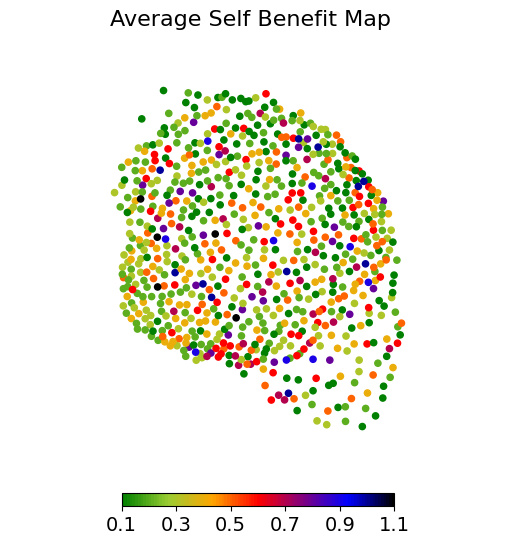

In [347]:
experiment.print_map_2d_colored_by_feature(feature_id='avg_self_benefit', title = 'Average Self Benefit Map', saveas='avg_self_benefit_map.pdf')

In [6]:
experiment2 = mapof.prepare_online_marriages_experiment()

In [7]:
experiment2.add_family(culture_id = 'reverse_euclidean', size = 100, label = 'Semi-Euclidean', color = 'red')

experiment2.add_family(culture_id = 'norm-mallows', size = 150, label="Mallows-Identical", color = 'blue')

experiment2.add_family(culture_id = 'asymmetric', size = 150, label = 'Mallows-MD', color = 'green')

experiment2.add_family(culture_id = 'symmetric', size = 150, label = 'Mallows-MA', color = 'orange')

experiment2.add_family(culture_id = 'mallows_euclidean', size = 150, label = 'Mallows-Euclidean', color = 'purple')

experiment2.add_family(culture_id = 'expectation', size = 100, label = 'Expectation-Euclidean', color = 'brown')

['expectation_10_0',
 'expectation_10_1',
 'expectation_10_2',
 'expectation_10_3',
 'expectation_10_4',
 'expectation_10_5',
 'expectation_10_6',
 'expectation_10_7',
 'expectation_10_8',
 'expectation_10_9',
 'expectation_10_10',
 'expectation_10_11',
 'expectation_10_12',
 'expectation_10_13',
 'expectation_10_14',
 'expectation_10_15',
 'expectation_10_16',
 'expectation_10_17',
 'expectation_10_18',
 'expectation_10_19',
 'expectation_10_20',
 'expectation_10_21',
 'expectation_10_22',
 'expectation_10_23',
 'expectation_10_24',
 'expectation_10_25',
 'expectation_10_26',
 'expectation_10_27',
 'expectation_10_28',
 'expectation_10_29',
 'expectation_10_30',
 'expectation_10_31',
 'expectation_10_32',
 'expectation_10_33',
 'expectation_10_34',
 'expectation_10_35',
 'expectation_10_36',
 'expectation_10_37',
 'expectation_10_38',
 'expectation_10_39',
 'expectation_10_40',
 'expectation_10_41',
 'expectation_10_42',
 'expectation_10_43',
 'expectation_10_44',
 'expectation_10_45'

In [8]:
reverse_euc_counter = 0
mallows_counter = 0
mallows_MD_counter = 0
mallows_MA_counter = 0
mallows_euclidean_counter = 0
expectations_euclidean_counter = 0

for key in experiment2.instances.keys():
    if key.startswith('reverse_euclidean'):
        experiment2.instances[key].votes = future_votes_rev_euclidean[reverse_euc_counter]
        experiment2.instances[key].features['avg_self_benefit'] = rev_euclid_feature[reverse_euc_counter]
        reverse_euc_counter += 30
    elif key.startswith('norm-mallows_'):
        experiment2.instances[key].votes = future_votes_mallows[mallows_counter]
        experiment2.instances[key].features['avg_self_benefit'] = mallows_feature[mallows_counter]
        mallows_counter += 24
    elif key.startswith('asymmetric_'):
        experiment2.instances[key].votes = future_votes_mallows_MD[mallows_MD_counter]
        experiment2.instances[key].features['avg_self_benefit'] = mallows_MD_feature[mallows_MD_counter]
        mallows_MD_counter += 24
    elif key.startswith('symmetric_'):  
        experiment2.instances[key].votes = future_votes_mallows_MA[mallows_MA_counter]
        experiment2.instances[key].features['avg_self_benefit'] = mallows_MA_feature[mallows_MA_counter]
        mallows_MA_counter += 24
    elif key.startswith('mallows_euclidean_'):
        experiment2.instances[key].votes = future_votes_mallows_euclidean[mallows_euclidean_counter]
        experiment2.instances[key].features['avg_self_benefit'] = mallows_euclidean_feature[mallows_euclidean_counter]
        mallows_euclidean_counter += 24
    elif key.startswith('expectation_'):
        experiment2.instances[key].votes = future_votes_expectations_euclidean[expectations_euclidean_counter]
        experiment2.instances[key].features['avg_self_benefit'] = expectations_euclidean_feature[expectations_euclidean_counter]
        expectations_euclidean_counter += 30



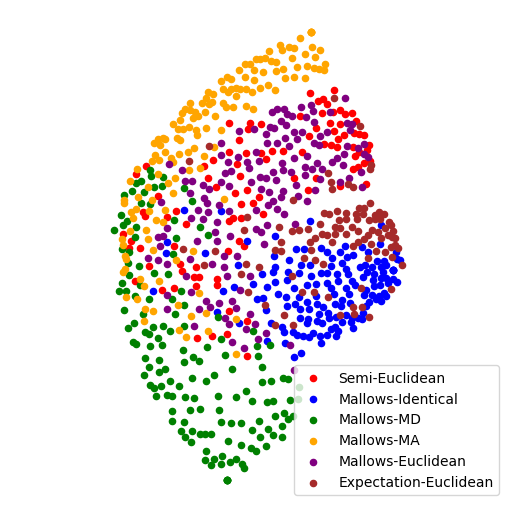

In [9]:
experiment2.compute_distances(distance_id='l1-mutual_attraction')
experiment2.embed_2d(embedding_id='kk')
experiment2.print_map_2d()

In [352]:
future_votes_rev_euclidean = reverse_euclid['preferences'].apply(literal_eval)
rev_euclid_feature = reverse_euclid['self_freq_instance']

future_votes_mallows = mallows['preferences'].apply(literal_eval)
mallows_feature = mallows['self_freq_instance']

future_votes_mallows_MD = mallows_MD['preferences'].apply(literal_eval)
mallows_MD_feature = mallows_MD['self_freq_instance']

future_votes_mallows_MA = mallows_MA['preferences'].apply(literal_eval)
mallows_MA_feature = mallows_MA['self_freq_instance']

future_votes_mallows_euclidean = mallows_euclidean['preferences'].apply(literal_eval)
mallows_euclidean_feature = mallows_euclidean['self_freq_instance']

future_votes_expectations_euclidean = expectations_euclidean['preferences'].apply(literal_eval)
expectations_euclidean_feature = expectations_euclidean['self_freq_instance']

In [369]:
f = []
for item in mallows_feature:
    if item not in f:
        f.append(item)

In [370]:
f

[0, 1]

In [353]:
rev_euclid_feature, future_votes_rev_euclidean = zip(*[
    (fval, fv)
    for fval, fv in zip(rev_euclid_feature, future_votes_rev_euclidean)
    #if fval != 0 and fval <= 1.1
])
rev_euclid_feature = list(rev_euclid_feature)
future_votes_rev_euclidean = list(future_votes_rev_euclidean)

mallows_feature, future_votes_mallows = zip(*[
    (fval, fv)
    for fval, fv in zip(mallows_feature, future_votes_mallows)
    #if fval != 0 and fval <= 1.1
])
mallows_feature = list(mallows_feature)
future_votes_mallows = list(future_votes_mallows)

mallows_MD_feature, future_votes_mallows_MD = zip(*[
    (fval, fv)
    for fval, fv in zip(mallows_MD_feature, future_votes_mallows_MD)
    #if fval != 0 and fval <= 1.1
])
mallows_MD_feature = list(mallows_MD_feature)
future_votes_mallows_MD = list(future_votes_mallows_MD)

mallows_MA_feature, future_votes_mallows_MA = zip(*[
    (fval, fv)
    for fval, fv in zip(mallows_MA_feature, future_votes_mallows_MA)
    #if fval != 0 and fval <= 1.1
])
mallows_MA_feature = list(mallows_MA_feature)
future_votes_mallows_MA = list(future_votes_mallows_MA)

mallows_euclidean_feature, future_votes_mallows_euclidean = zip(*[
    (fval, fv)
    for fval, fv in zip(mallows_euclidean_feature, future_votes_mallows_euclidean)
    #if fval != 0 and fval <= 1.1
])
mallows_euclidean_feature = list(mallows_euclidean_feature)
future_votes_mallows_euclidean = list(future_votes_mallows_euclidean)

expectations_euclidean_feature, future_votes_expectations_euclidean = zip(*[
    (fval, fv)
    for fval, fv in zip(expectations_euclidean_feature, future_votes_expectations_euclidean)
    #if fval != 0 and fval <= 1.1
])
expectations_euclidean_feature = list(expectations_euclidean_feature)
future_votes_expectations_euclidean = list(future_votes_expectations_euclidean)

In [354]:
for i in range(len(future_votes_rev_euclidean)):
        future_votes_rev_euclidean[i][0] = np.array(future_votes_rev_euclidean[i][0]) -1
        future_votes_rev_euclidean[i][1] =  np.array(future_votes_rev_euclidean[i][1]) -1
for i in range(len(future_votes_mallows)):
        future_votes_mallows[i][0] = np.array(future_votes_mallows[i][0]) -1
        future_votes_mallows[i][1] =  np.array(future_votes_mallows[i][1]) -1

for i in range(len(future_votes_mallows_MD)):
        future_votes_mallows_MD[i][0] = np.array(future_votes_mallows_MD[i][0]) -1
        future_votes_mallows_MD[i][1] =  np.array(future_votes_mallows_MD[i][1]) -1

for i in range(len(future_votes_mallows_MA)):
        future_votes_mallows_MA[i][0] = np.array(future_votes_mallows_MA[i][0]) -1
        future_votes_mallows_MA[i][1] =  np.array(future_votes_mallows_MA[i][1]) -1

for i in range(len(future_votes_mallows_euclidean)):
        future_votes_mallows_euclidean[i][0] = np.array(future_votes_mallows_euclidean[i][0]) -1
        future_votes_mallows_euclidean[i][1] =  np.array(future_votes_mallows_euclidean[i][1]) -1

for i in range(len(future_votes_expectations_euclidean)):
        future_votes_expectations_euclidean[i][0] = np.array(future_votes_expectations_euclidean[i][0]) -1
        future_votes_expectations_euclidean[i][1] =  np.array(future_votes_expectations_euclidean[i][1]) -1

In [355]:
len(future_votes_rev_euclidean), len(future_votes_mallows), len(future_votes_mallows_MD), len(future_votes_mallows_MA), len(future_votes_mallows_euclidean), len(future_votes_expectations_euclidean)

(3000, 3600, 3600, 3600, 3600, 3000)

In [360]:
experiment3 = mapof.prepare_online_marriages_experiment()

In [361]:
experiment3.add_family(culture_id = 'reverse_euclidean', size = 100, label = 'Semi-Euclidean')

experiment3.add_family(culture_id = 'norm-mallows', size = 150, label="Mallows-Identical")

experiment3.add_family(culture_id = 'asymmetric', size = 150, label = 'Mallows-MD')

experiment3.add_family(culture_id = 'symmetric', size = 150, label = 'Mallows-MA')

experiment3.add_family(culture_id = 'mallows_euclidean', size = 150, label = 'Mallows-Euclidean')

experiment3.add_family(culture_id = 'expectation', size = 100, label = 'Expectation-Euclidean')

['expectation_10_0',
 'expectation_10_1',
 'expectation_10_2',
 'expectation_10_3',
 'expectation_10_4',
 'expectation_10_5',
 'expectation_10_6',
 'expectation_10_7',
 'expectation_10_8',
 'expectation_10_9',
 'expectation_10_10',
 'expectation_10_11',
 'expectation_10_12',
 'expectation_10_13',
 'expectation_10_14',
 'expectation_10_15',
 'expectation_10_16',
 'expectation_10_17',
 'expectation_10_18',
 'expectation_10_19',
 'expectation_10_20',
 'expectation_10_21',
 'expectation_10_22',
 'expectation_10_23',
 'expectation_10_24',
 'expectation_10_25',
 'expectation_10_26',
 'expectation_10_27',
 'expectation_10_28',
 'expectation_10_29',
 'expectation_10_30',
 'expectation_10_31',
 'expectation_10_32',
 'expectation_10_33',
 'expectation_10_34',
 'expectation_10_35',
 'expectation_10_36',
 'expectation_10_37',
 'expectation_10_38',
 'expectation_10_39',
 'expectation_10_40',
 'expectation_10_41',
 'expectation_10_42',
 'expectation_10_43',
 'expectation_10_44',
 'expectation_10_45'

In [362]:
reverse_euc_counter = 0
mallows_counter = 0
mallows_MD_counter = 0
mallows_MA_counter = 0
mallows_euclidean_counter = 0
expectations_euclidean_counter = 0

for key in experiment3.instances.keys():
    if key.startswith('reverse_euclidean'):
        experiment3.instances[key].votes = future_votes_rev_euclidean[reverse_euc_counter]
        experiment3.instances[key].features['self_freq_instance'] = rev_euclid_feature[reverse_euc_counter]
        reverse_euc_counter += 30
    elif key.startswith('norm-mallows_'):
        experiment3.instances[key].votes = future_votes_mallows[mallows_counter]
        experiment3.instances[key].features['self_freq_instance'] = mallows_feature[mallows_counter]
        mallows_counter += 24
    elif key.startswith('asymmetric_'):
        experiment3.instances[key].votes = future_votes_mallows_MD[mallows_MD_counter]
        experiment3.instances[key].features['self_freq_instance'] = mallows_MD_feature[mallows_MD_counter]
        mallows_MD_counter += 24
    elif key.startswith('symmetric_'):
        experiment3.instances[key].votes = future_votes_mallows_MA[mallows_MA_counter]
        experiment3.instances[key].features['self_freq_instance'] = mallows_MA_feature[mallows_MA_counter]
        mallows_MA_counter += 24
    elif key.startswith('mallows_euclidean_'):
        experiment3.instances[key].votes = future_votes_mallows_euclidean[mallows_euclidean_counter]
        experiment3.instances[key].features['self_freq_instance'] = mallows_euclidean_feature[mallows_euclidean_counter]
        mallows_euclidean_counter += 24
    elif key.startswith('expectation_'):
        experiment3.instances[key].votes = future_votes_expectations_euclidean[expectations_euclidean_counter]
        experiment3.instances[key].features['self_freq_instance'] = expectations_euclidean_feature[expectations_euclidean_counter]
        expectations_euclidean_counter += 30



In [363]:
experiment3.compute_distances(distance_id='l1-mutual_attraction')
experiment3.embed_2d(embedding_id='kk')

In [364]:
experiment3.features['self_freq_instance'] = {'value':{}}

In [365]:
for key in experiment3.instances.keys():
    experiment3.features['self_freq_instance']['value'][key] = (experiment3.instances[key].features['self_freq_instance'])

In [366]:
experiment3.experiment_id = 'self_manipulation_frequency'

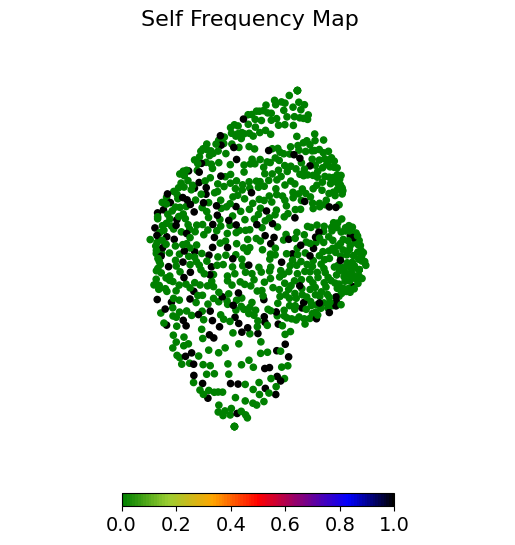

In [368]:
experiment3.print_map_2d_colored_by_feature(feature_id='self_freq_instance', title = 'Self Frequency Map', saveas='self_freq_map.pdf')

In [371]:
experiment4 = mapof.prepare_online_marriages_experiment()

In [372]:
experiment4.add_family(culture_id = 'reverse_euclidean', size = 100, label = 'Semi-Euclidean', color = 'red')

experiment4.add_family(culture_id = 'norm-mallows', size = 150, label="Mallows-Identical", color = 'blue')

experiment4.add_family(culture_id = 'asymmetric', size = 150, label = 'Mallows-MD', color = 'green')

experiment4.add_family(culture_id = 'symmetric', size = 150, label = 'Mallows-MA', color = 'orange')

experiment4.add_family(culture_id = 'mallows_euclidean', size = 150, label = 'Mallows-Euclidean', color = 'purple')

experiment4.add_family(culture_id = 'expectation', size = 100, label = 'Expectation-Euclidean', color = 'brown')

['expectation_10_0',
 'expectation_10_1',
 'expectation_10_2',
 'expectation_10_3',
 'expectation_10_4',
 'expectation_10_5',
 'expectation_10_6',
 'expectation_10_7',
 'expectation_10_8',
 'expectation_10_9',
 'expectation_10_10',
 'expectation_10_11',
 'expectation_10_12',
 'expectation_10_13',
 'expectation_10_14',
 'expectation_10_15',
 'expectation_10_16',
 'expectation_10_17',
 'expectation_10_18',
 'expectation_10_19',
 'expectation_10_20',
 'expectation_10_21',
 'expectation_10_22',
 'expectation_10_23',
 'expectation_10_24',
 'expectation_10_25',
 'expectation_10_26',
 'expectation_10_27',
 'expectation_10_28',
 'expectation_10_29',
 'expectation_10_30',
 'expectation_10_31',
 'expectation_10_32',
 'expectation_10_33',
 'expectation_10_34',
 'expectation_10_35',
 'expectation_10_36',
 'expectation_10_37',
 'expectation_10_38',
 'expectation_10_39',
 'expectation_10_40',
 'expectation_10_41',
 'expectation_10_42',
 'expectation_10_43',
 'expectation_10_44',
 'expectation_10_45'

In [373]:
reverse_euc_counter = 0
mallows_counter = 0
mallows_MD_counter = 0
mallows_MA_counter = 0
mallows_euclidean_counter = 0
expectations_euclidean_counter = 0

for key in experiment4.instances.keys():
    if key.startswith('reverse_euclidean'):
        experiment4.instances[key].votes = future_votes_rev_euclidean[reverse_euc_counter]
        #experiment4.instances[key].features['self_freq_instance'] = rev_euclid_feature[reverse_euc_counter]
        reverse_euc_counter += 30
    elif key.startswith('norm-mallows_'):
        experiment4.instances[key].votes = future_votes_mallows[mallows_counter]
        #experiment4.instances[key].features['self_freq_instance'] = mallows_feature[mallows_counter]
        mallows_counter += 24
    elif key.startswith('asymmetric_'):
        experiment4.instances[key].votes = future_votes_mallows_MD[mallows_MD_counter]
        #experiment4.instances[key].features['self_freq_instance'] = mallows_MD_feature[mallows_MD_counter]
        mallows_MD_counter += 24
    elif key.startswith('symmetric_'):
        experiment4.instances[key].votes = future_votes_mallows_MA[mallows_MA_counter]
        #experiment4.instances[key].features['self_freq_instance'] = mallows_MA_feature[mallows_MA_counter]
        mallows_MA_counter += 24
    elif key.startswith('mallows_euclidean_'):
        experiment4.instances[key].votes = future_votes_mallows_euclidean[mallows_euclidean_counter]
        #experiment4.instances[key].features['self_freq_instance'] = mallows_euclidean_feature[mallows_euclidean_counter]
        mallows_euclidean_counter += 24
    elif key.startswith('expectation_'):
        experiment4.instances[key].votes = future_votes_expectations_euclidean[expectations_euclidean_counter]
        #experiment4.instances[key].features['self_freq_instance'] = expectations_euclidean_feature[expectations_euclidean_counter]
        expectations_euclidean_counter += 30



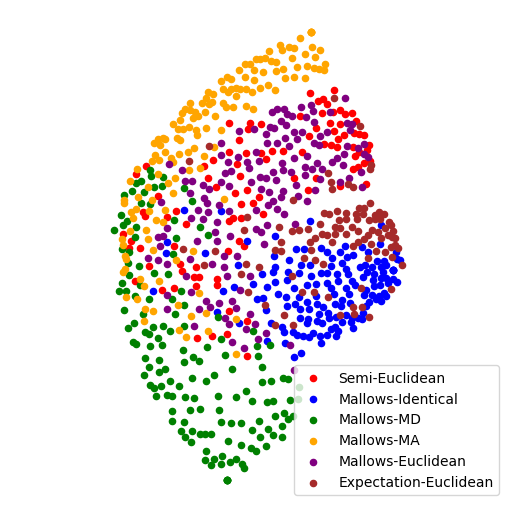

In [374]:
experiment4.compute_distances(distance_id='l1-mutual_attraction')
experiment4.embed_2d(embedding_id='kk')
experiment4.print_map_2d()

In [406]:
future_votes_rev_euclidean = reverse_euclid['preferences'].apply(literal_eval)
rev_euclid_feature = reverse_euclid['num_self_manipulators']

future_votes_mallows = mallows['preferences'].apply(literal_eval)
mallows_feature = mallows['num_self_manipulators']

future_votes_mallows_MD = mallows_MD['preferences'].apply(literal_eval)
mallows_MD_feature = mallows_MD['num_self_manipulators']

future_votes_mallows_MA = mallows_MA['preferences'].apply(literal_eval)
mallows_MA_feature = mallows_MA['num_self_manipulators']

future_votes_mallows_euclidean = mallows_euclidean['preferences'].apply(literal_eval)
mallows_euclidean_feature = mallows_euclidean['num_self_manipulators']

future_votes_expectations_euclidean = expectations_euclidean['preferences'].apply(literal_eval)
expectations_euclidean_feature = expectations_euclidean['num_self_manipulators']

In [407]:
rev_euclid_feature, future_votes_rev_euclidean = zip(*[
    (fval, fv)
    for fval, fv in zip(rev_euclid_feature, future_votes_rev_euclidean)
    if fval != 0
])
rev_euclid_feature = list(rev_euclid_feature)
future_votes_rev_euclidean = list(future_votes_rev_euclidean)

mallows_feature, future_votes_mallows = zip(*[
    (fval, fv)
    for fval, fv in zip(mallows_feature, future_votes_mallows)
    if fval != 0
])
mallows_feature = list(mallows_feature)
future_votes_mallows = list(future_votes_mallows)

mallows_MD_feature, future_votes_mallows_MD = zip(*[
    (fval, fv)
    for fval, fv in zip(mallows_MD_feature, future_votes_mallows_MD)
    if fval != 0
])
mallows_MD_feature = list(mallows_MD_feature)
future_votes_mallows_MD = list(future_votes_mallows_MD)

mallows_MA_feature, future_votes_mallows_MA = zip(*[
    (fval, fv)
    for fval, fv in zip(mallows_MA_feature, future_votes_mallows_MA)
    if fval != 0
])
mallows_MA_feature = list(mallows_MA_feature)
future_votes_mallows_MA = list(future_votes_mallows_MA)

mallows_euclidean_feature, future_votes_mallows_euclidean = zip(*[
    (fval, fv)
    for fval, fv in zip(mallows_euclidean_feature, future_votes_mallows_euclidean)
    if fval != 0
])
mallows_euclidean_feature = list(mallows_euclidean_feature)
future_votes_mallows_euclidean = list(future_votes_mallows_euclidean)

expectations_euclidean_feature, future_votes_expectations_euclidean = zip(*[
    (fval, fv)
    for fval, fv in zip(expectations_euclidean_feature, future_votes_expectations_euclidean)
    if fval != 0
])
expectations_euclidean_feature = list(expectations_euclidean_feature)
future_votes_expectations_euclidean = list(future_votes_expectations_euclidean)

In [389]:
len(future_votes_rev_euclidean), len(future_votes_mallows), len(future_votes_mallows_MD), len(future_votes_mallows_MA), len(future_votes_mallows_euclidean), len(future_votes_expectations_euclidean)

(282, 484, 823, 495, 736, 393)

In [408]:
future_votes_mallows_MD = future_votes_mallows_MD[0:822]

In [409]:
for i in range(len(future_votes_rev_euclidean)):
        future_votes_rev_euclidean[i][0] = np.array(future_votes_rev_euclidean[i][0]) -1
        future_votes_rev_euclidean[i][1] =  np.array(future_votes_rev_euclidean[i][1]) -1
for i in range(len(future_votes_mallows)):
        future_votes_mallows[i][0] = np.array(future_votes_mallows[i][0]) -1
        future_votes_mallows[i][1] =  np.array(future_votes_mallows[i][1]) -1

for i in range(len(future_votes_mallows_MD)):
        future_votes_mallows_MD[i][0] = np.array(future_votes_mallows_MD[i][0]) -1
        future_votes_mallows_MD[i][1] =  np.array(future_votes_mallows_MD[i][1]) -1

for i in range(len(future_votes_mallows_MA)):
        future_votes_mallows_MA[i][0] = np.array(future_votes_mallows_MA[i][0]) -1
        future_votes_mallows_MA[i][1] =  np.array(future_votes_mallows_MA[i][1]) -1

for i in range(len(future_votes_mallows_euclidean)):
        future_votes_mallows_euclidean[i][0] = np.array(future_votes_mallows_euclidean[i][0]) -1
        future_votes_mallows_euclidean[i][1] =  np.array(future_votes_mallows_euclidean[i][1]) -1

for i in range(len(future_votes_expectations_euclidean)):
        future_votes_expectations_euclidean[i][0] = np.array(future_votes_expectations_euclidean[i][0]) -1
        future_votes_expectations_euclidean[i][1] =  np.array(future_votes_expectations_euclidean[i][1]) -1

In [411]:
experiment5 = mapof.prepare_online_marriages_experiment()

In [412]:
experiment5.add_family(culture_id = 'reverse_euclidean', size = 141, label = 'Semi-Euclidean')

experiment5.add_family(culture_id = 'norm-mallows', size = 121, label="Mallows-Identical")

experiment5.add_family(culture_id = 'asymmetric', size = 137, label = 'Mallows-MD')

experiment5.add_family(culture_id = 'symmetric', size = 99, label = 'Mallows-MA')

experiment5.add_family(culture_id = 'mallows_euclidean', size = 92, label = 'Mallows-Euclidean')

experiment5.add_family(culture_id = 'expectation', size = 131, label = 'Expectation-Euclidean')

['expectation_10_0',
 'expectation_10_1',
 'expectation_10_2',
 'expectation_10_3',
 'expectation_10_4',
 'expectation_10_5',
 'expectation_10_6',
 'expectation_10_7',
 'expectation_10_8',
 'expectation_10_9',
 'expectation_10_10',
 'expectation_10_11',
 'expectation_10_12',
 'expectation_10_13',
 'expectation_10_14',
 'expectation_10_15',
 'expectation_10_16',
 'expectation_10_17',
 'expectation_10_18',
 'expectation_10_19',
 'expectation_10_20',
 'expectation_10_21',
 'expectation_10_22',
 'expectation_10_23',
 'expectation_10_24',
 'expectation_10_25',
 'expectation_10_26',
 'expectation_10_27',
 'expectation_10_28',
 'expectation_10_29',
 'expectation_10_30',
 'expectation_10_31',
 'expectation_10_32',
 'expectation_10_33',
 'expectation_10_34',
 'expectation_10_35',
 'expectation_10_36',
 'expectation_10_37',
 'expectation_10_38',
 'expectation_10_39',
 'expectation_10_40',
 'expectation_10_41',
 'expectation_10_42',
 'expectation_10_43',
 'expectation_10_44',
 'expectation_10_45'

In [413]:
reverse_euc_counter = 0
mallows_counter = 0
mallows_MD_counter = 0
mallows_MA_counter = 0
mallows_euclidean_counter = 0
expectations_euclidean_counter = 0

for key in experiment5.instances.keys():
    if key.startswith('reverse_euclidean'):
        experiment5.instances[key].votes = future_votes_rev_euclidean[reverse_euc_counter]
        experiment5.instances[key].features['num_self_manipulators'] = rev_euclid_feature[reverse_euc_counter]
        reverse_euc_counter += 2
    elif key.startswith('norm-mallows_'):
        experiment5.instances[key].votes = future_votes_mallows[mallows_counter]
        experiment5.instances[key].features['num_self_manipulators'] = mallows_feature[mallows_counter]
        mallows_counter += 4
    elif key.startswith('asymmetric_'):
        experiment5.instances[key].votes = future_votes_mallows_MD[mallows_MD_counter]
        experiment5.instances[key].features['num_self_manipulators'] = mallows_MD_feature[mallows_MD_counter]
        mallows_MD_counter += 6
    elif key.startswith('symmetric_'):
        experiment5.instances[key].votes = future_votes_mallows_MA[mallows_MA_counter]
        experiment5.instances[key].features['num_self_manipulators'] = mallows_MA_feature[mallows_MA_counter]
        mallows_MA_counter += 5
    elif key.startswith('mallows_euclidean_'):
        experiment5.instances[key].votes = future_votes_mallows_euclidean[mallows_euclidean_counter]
        experiment5.instances[key].features['num_self_manipulators'] = mallows_euclidean_feature[mallows_euclidean_counter]
        mallows_euclidean_counter += 8
    elif key.startswith('expectation_'):
        experiment5.instances[key].votes = future_votes_expectations_euclidean[expectations_euclidean_counter]
        experiment5.instances[key].features['num_self_manipulators'] = expectations_euclidean_feature[expectations_euclidean_counter]
        expectations_euclidean_counter += 3



In [414]:
experiment5.compute_distances(distance_id='l1-mutual_attraction')
experiment5.embed_2d(embedding_id='kk')

/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/mapof/core/embedding/kamada_kawai/optimization_algorithms.py:56: RuntimeWarning: invalid value encountered in divide
  step_size = np.linalg.norm(s, axis=0) ** 2 / denominator
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/mapof/core/embedding/kamada_kawai/optimization_algorithms.py:56: RuntimeWarning: divide by zero encountered in divide
  step_size = np.linalg.norm(s, axis=0) ** 2 / denominator
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/mapof/core/embedding/kamada_kawai/optimization_algorithms.py:62: RuntimeWarning: invalid value encountered in multiply
  x = x - step_size * g
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/mapof/core/embedding/kamada_kawai/energy_functions.py:5: RuntimeWarning: invalid value encountered in subtract
  positions_delta = positions[:, np.newaxis, :] - positions[np.newaxis, :

In [415]:
experiment5.features['num_self_manipulators'] = {'value':{}}

In [416]:
for key in experiment5.instances.keys():
    experiment5.features['num_self_manipulators']['value'][key] = (experiment5.instances[key].features['num_self_manipulators'])

In [417]:
experiment5.experiment_id = 'self_manipulation_count'

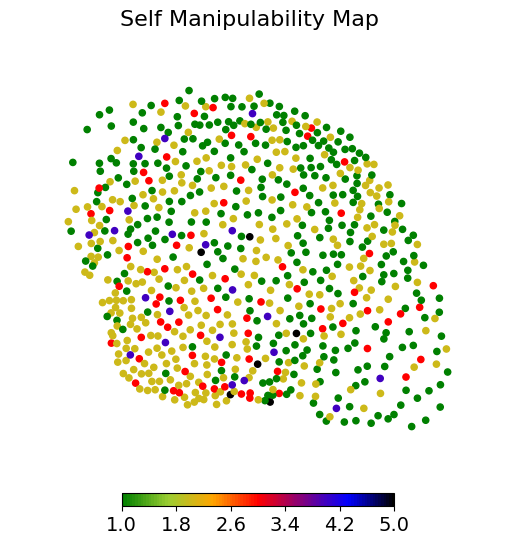

In [418]:
experiment5.print_map_2d_colored_by_feature(feature_id='num_self_manipulators', title = 'Self Manipulability Map', saveas='self_manipulability_map.pdf')

In [419]:
experiment6 = mapof.prepare_online_marriages_experiment()

In [420]:
experiment6.add_family(culture_id = 'reverse_euclidean', size = 141, label = 'Semi-Euclidean', color = 'red')

experiment6.add_family(culture_id = 'norm-mallows', size = 121, label="Mallows-Identical", color = 'blue')

experiment6.add_family(culture_id = 'asymmetric', size = 137, label = 'Mallows-MD', color = 'green')

experiment6.add_family(culture_id = 'symmetric', size = 99, label = 'Mallows-MA', color = 'orange')

experiment6.add_family(culture_id = 'mallows_euclidean', size = 92, label = 'Mallows-Euclidean', color = 'purple')

experiment6.add_family(culture_id = 'expectation', size = 131, label = 'Expectation-Euclidean', color = 'brown')

['expectation_10_0',
 'expectation_10_1',
 'expectation_10_2',
 'expectation_10_3',
 'expectation_10_4',
 'expectation_10_5',
 'expectation_10_6',
 'expectation_10_7',
 'expectation_10_8',
 'expectation_10_9',
 'expectation_10_10',
 'expectation_10_11',
 'expectation_10_12',
 'expectation_10_13',
 'expectation_10_14',
 'expectation_10_15',
 'expectation_10_16',
 'expectation_10_17',
 'expectation_10_18',
 'expectation_10_19',
 'expectation_10_20',
 'expectation_10_21',
 'expectation_10_22',
 'expectation_10_23',
 'expectation_10_24',
 'expectation_10_25',
 'expectation_10_26',
 'expectation_10_27',
 'expectation_10_28',
 'expectation_10_29',
 'expectation_10_30',
 'expectation_10_31',
 'expectation_10_32',
 'expectation_10_33',
 'expectation_10_34',
 'expectation_10_35',
 'expectation_10_36',
 'expectation_10_37',
 'expectation_10_38',
 'expectation_10_39',
 'expectation_10_40',
 'expectation_10_41',
 'expectation_10_42',
 'expectation_10_43',
 'expectation_10_44',
 'expectation_10_45'

In [421]:
reverse_euc_counter = 0
mallows_counter = 0
mallows_MD_counter = 0
mallows_MA_counter = 0
mallows_euclidean_counter = 0
expectations_euclidean_counter = 0

for key in experiment6.instances.keys():
    if key.startswith('reverse_euclidean'):
        experiment6.instances[key].votes = future_votes_rev_euclidean[reverse_euc_counter]
        #experiment4.instances[key].features['self_freq_instance'] = rev_euclid_feature[reverse_euc_counter]
        reverse_euc_counter += 2
    elif key.startswith('norm-mallows_'):
        experiment6.instances[key].votes = future_votes_mallows[mallows_counter]
        #experiment4.instances[key].features['self_freq_instance'] = mallows_feature[mallows_counter]
        mallows_counter += 4
    elif key.startswith('asymmetric_'):
        experiment6.instances[key].votes = future_votes_mallows_MD[mallows_MD_counter]
        #experiment4.instances[key].features['self_freq_instance'] = mallows_MD_feature[mallows_MD_counter]
        mallows_MD_counter += 6
    elif key.startswith('symmetric_'):
        experiment6.instances[key].votes = future_votes_mallows_MA[mallows_MA_counter]
        #experiment4.instances[key].features['self_freq_instance'] = mallows_MA_feature[mallows_MA_counter]
        mallows_MA_counter += 5
    elif key.startswith('mallows_euclidean_'):
        experiment6.instances[key].votes = future_votes_mallows_euclidean[mallows_euclidean_counter]
        #experiment4.instances[key].features['self_freq_instance'] = mallows_euclidean_feature[mallows_euclidean_counter]
        mallows_euclidean_counter += 8
    elif key.startswith('expectation_'):
        experiment6.instances[key].votes = future_votes_expectations_euclidean[expectations_euclidean_counter]
        #experiment4.instances[key].features['self_freq_instance'] = expectations_euclidean_feature[expectations_euclidean_counter]
        expectations_euclidean_counter += 3



/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/mapof/core/embedding/kamada_kawai/optimization_algorithms.py:56: RuntimeWarning: invalid value encountered in divide
  step_size = np.linalg.norm(s, axis=0) ** 2 / denominator
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/mapof/core/embedding/kamada_kawai/optimization_algorithms.py:56: RuntimeWarning: divide by zero encountered in divide
  step_size = np.linalg.norm(s, axis=0) ** 2 / denominator
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/mapof/core/embedding/kamada_kawai/optimization_algorithms.py:62: RuntimeWarning: invalid value encountered in multiply
  x = x - step_size * g
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/mapof/core/embedding/kamada_kawai/energy_functions.py:5: RuntimeWarning: invalid value encountered in subtract
  positions_delta = positions[:, np.newaxis, :] - positions[np.newaxis, :

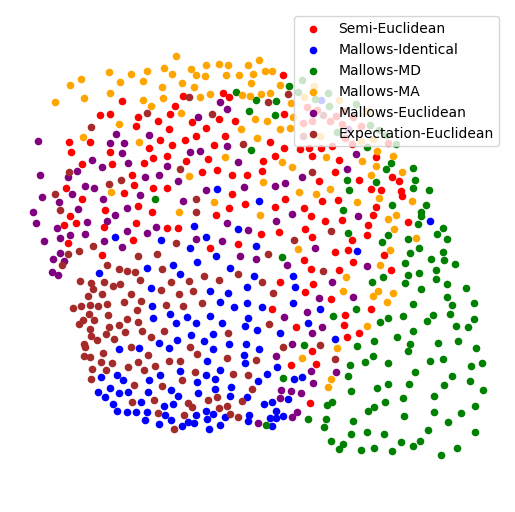

In [422]:
experiment6.compute_distances(distance_id='l1-mutual_attraction')
experiment6.embed_2d(embedding_id='kk')
experiment6.print_map_2d()

In [439]:
reverse_euclid = pandas.read_csv('reverse_euclidean_gain_with_rank_diff.csv')
mallows = pandas.read_csv('mallows_gain_with_rank_diff.csv')
mallows_MD = pandas.read_csv('mallows_MD_gain_with_rank_diff.csv')
mallows_MA = pandas.read_csv('mallows_MA_gain_with_rank_diff.csv')
mallows_euclidean = pandas.read_csv('mallows_euclidean_gain_with_rank_diff.csv')
expectations_euclidean = pandas.read_csv('expectations_euclidean_gain_with_rank_diff.csv')

In [440]:
future_votes_rev_euclidean = reverse_euclid['preferences'].apply(literal_eval)
rev_euclid_feature = reverse_euclid['trunc_count']

future_votes_mallows = mallows['preferences'].apply(literal_eval)
mallows_feature = mallows['trunc_count']

future_votes_mallows_MD = mallows_MD['preferences'].apply(literal_eval)
mallows_MD_feature = mallows_MD['trunc_count']

future_votes_mallows_MA = mallows_MA['preferences'].apply(literal_eval)
mallows_MA_feature = mallows_MA['trunc_count']

future_votes_mallows_euclidean = mallows_euclidean['preferences'].apply(literal_eval)
mallows_euclidean_feature = mallows_euclidean['trunc_count']

future_votes_expectations_euclidean = expectations_euclidean['preferences'].apply(literal_eval)
expectations_euclidean_feature = expectations_euclidean['trunc_count']

In [ ]:
rev_euclid_feature, future_votes_rev_euclidean = zip(*[
    (fval, fv)
    for fval, fv in zip(rev_euclid_feature, future_votes_rev_euclidean)
    if fval != 0 #to get back to other map that includes 0s, comment out this line for all 6 cultures
])
rev_euclid_feature = list(rev_euclid_feature)
future_votes_rev_euclidean = list(future_votes_rev_euclidean)

mallows_feature, future_votes_mallows = zip(*[
    (fval, fv)
    for fval, fv in zip(mallows_feature, future_votes_mallows)
    if fval != 0
])
mallows_feature = list(mallows_feature)
future_votes_mallows = list(future_votes_mallows)

mallows_MD_feature, future_votes_mallows_MD = zip(*[
    (fval, fv)
    for fval, fv in zip(mallows_MD_feature, future_votes_mallows_MD)
    if fval != 0
])
mallows_MD_feature = list(mallows_MD_feature)
future_votes_mallows_MD = list(future_votes_mallows_MD)

mallows_MA_feature, future_votes_mallows_MA = zip(*[
    (fval, fv)
    for fval, fv in zip(mallows_MA_feature, future_votes_mallows_MA)
    if fval != 0
])
mallows_MA_feature = list(mallows_MA_feature)
future_votes_mallows_MA = list(future_votes_mallows_MA)

mallows_euclidean_feature, future_votes_mallows_euclidean = zip(*[
    (fval, fv)
    for fval, fv in zip(mallows_euclidean_feature, future_votes_mallows_euclidean)
    if fval != 0
])
mallows_euclidean_feature = list(mallows_euclidean_feature)
future_votes_mallows_euclidean = list(future_votes_mallows_euclidean)

expectations_euclidean_feature, future_votes_expectations_euclidean = zip(*[
    (fval, fv)
    for fval, fv in zip(expectations_euclidean_feature, future_votes_expectations_euclidean)
    if fval != 0
])
expectations_euclidean_feature = list(expectations_euclidean_feature)
future_votes_expectations_euclidean = list(future_votes_expectations_euclidean)

In [442]:
for i in range(len(future_votes_rev_euclidean)):
        future_votes_rev_euclidean[i][0] = np.array(future_votes_rev_euclidean[i][0]) -1
        future_votes_rev_euclidean[i][1] =  np.array(future_votes_rev_euclidean[i][1]) -1
for i in range(len(future_votes_mallows)):
        future_votes_mallows[i][0] = np.array(future_votes_mallows[i][0]) -1
        future_votes_mallows[i][1] =  np.array(future_votes_mallows[i][1]) -1

for i in range(len(future_votes_mallows_MD)):
        future_votes_mallows_MD[i][0] = np.array(future_votes_mallows_MD[i][0]) -1
        future_votes_mallows_MD[i][1] =  np.array(future_votes_mallows_MD[i][1]) -1

for i in range(len(future_votes_mallows_MA)):
        future_votes_mallows_MA[i][0] = np.array(future_votes_mallows_MA[i][0]) -1
        future_votes_mallows_MA[i][1] =  np.array(future_votes_mallows_MA[i][1]) -1

for i in range(len(future_votes_mallows_euclidean)):
        future_votes_mallows_euclidean[i][0] = np.array(future_votes_mallows_euclidean[i][0]) -1
        future_votes_mallows_euclidean[i][1] =  np.array(future_votes_mallows_euclidean[i][1]) -1

for i in range(len(future_votes_expectations_euclidean)):
        future_votes_expectations_euclidean[i][0] = np.array(future_votes_expectations_euclidean[i][0]) -1
        future_votes_expectations_euclidean[i][1] =  np.array(future_votes_expectations_euclidean[i][1]) -1

In [444]:
len(future_votes_rev_euclidean), len(future_votes_mallows), len(future_votes_mallows_MD), len(future_votes_mallows_MA), len(future_votes_mallows_euclidean), len(future_votes_expectations_euclidean)

(1184, 953, 3456, 1902, 1686, 764)

In [445]:
future_votes_mallows = future_votes_mallows[0:952]
future_votes_mallow_MA = future_votes_mallows_MA[0:1900]
future_votes_mallows_euclidean = future_votes_mallows_euclidean[0:1680]
future_votes_expectations_euclidean = future_votes_expectations_euclidean[0:762]

In [446]:
experiment7 = mapof.prepare_online_marriages_experiment()

In [447]:
experiment7.add_family(culture_id = 'reverse_euclidean', size = 148, label = 'Semi-Euclidean')

experiment7.add_family(culture_id = 'norm-mallows', size = 136, label="Mallows-Identical")

experiment7.add_family(culture_id = 'asymmetric', size = 128, label = 'Mallows-MD')

experiment7.add_family(culture_id = 'symmetric', size = 100, label = 'Mallows-MA')

experiment7.add_family(culture_id = 'mallows_euclidean', size = 120, label = 'Mallows-Euclidean')

experiment7.add_family(culture_id = 'expectation', size = 127, label = 'Expectation-Euclidean')

['expectation_10_0',
 'expectation_10_1',
 'expectation_10_2',
 'expectation_10_3',
 'expectation_10_4',
 'expectation_10_5',
 'expectation_10_6',
 'expectation_10_7',
 'expectation_10_8',
 'expectation_10_9',
 'expectation_10_10',
 'expectation_10_11',
 'expectation_10_12',
 'expectation_10_13',
 'expectation_10_14',
 'expectation_10_15',
 'expectation_10_16',
 'expectation_10_17',
 'expectation_10_18',
 'expectation_10_19',
 'expectation_10_20',
 'expectation_10_21',
 'expectation_10_22',
 'expectation_10_23',
 'expectation_10_24',
 'expectation_10_25',
 'expectation_10_26',
 'expectation_10_27',
 'expectation_10_28',
 'expectation_10_29',
 'expectation_10_30',
 'expectation_10_31',
 'expectation_10_32',
 'expectation_10_33',
 'expectation_10_34',
 'expectation_10_35',
 'expectation_10_36',
 'expectation_10_37',
 'expectation_10_38',
 'expectation_10_39',
 'expectation_10_40',
 'expectation_10_41',
 'expectation_10_42',
 'expectation_10_43',
 'expectation_10_44',
 'expectation_10_45'

In [448]:
reverse_euc_counter = 0
mallows_counter = 0
mallows_MD_counter = 0
mallows_MA_counter = 0
mallows_euclidean_counter = 0
expectations_euclidean_counter = 0

for key in experiment7.instances.keys():
    if key.startswith('reverse_euclidean'):
        experiment7.instances[key].votes = future_votes_rev_euclidean[reverse_euc_counter]
        experiment7.instances[key].features['trunc_count'] = rev_euclid_feature[reverse_euc_counter]
        reverse_euc_counter += 8
    elif key.startswith('norm-mallows_'):
        experiment7.instances[key].votes = future_votes_mallows[mallows_counter]
        experiment7.instances[key].features['trunc_count'] = mallows_feature[mallows_counter]
        mallows_counter += 7
    elif key.startswith('asymmetric_'):
        experiment7.instances[key].votes = future_votes_mallows_MD[mallows_MD_counter]
        experiment7.instances[key].features['trunc_count'] = mallows_MD_feature[mallows_MD_counter]
        mallows_MD_counter += 27
    elif key.startswith('symmetric_'):
        experiment7.instances[key].votes = future_votes_mallows_MA[mallows_MA_counter]
        experiment7.instances[key].features['trunc_count'] = mallows_MA_feature[mallows_MA_counter]
        mallows_MA_counter += 19
    elif key.startswith('mallows_euclidean_'):
        experiment7.instances[key].votes = future_votes_mallows_euclidean[mallows_euclidean_counter]
        experiment7.instances[key].features['trunc_count'] = mallows_euclidean_feature[mallows_euclidean_counter]
        mallows_euclidean_counter += 14
    elif key.startswith('expectation_'):
        experiment7.instances[key].votes = future_votes_expectations_euclidean[expectations_euclidean_counter]
        experiment7.instances[key].features['trunc_count'] = expectations_euclidean_feature[expectations_euclidean_counter]
        expectations_euclidean_counter += 6

In [449]:
experiment7.compute_distances(distance_id='l1-mutual_attraction')
experiment7.embed_2d(embedding_id='kk')

In [450]:
experiment7.features['trunc_count'] = {'value':{}}

In [451]:
for key in experiment7.instances.keys():
    experiment7.features['trunc_count']['value'][key] = (experiment7.instances[key].features['trunc_count'])

In [452]:
experiment7.experiment_id = 'trunc_manipulation_count'

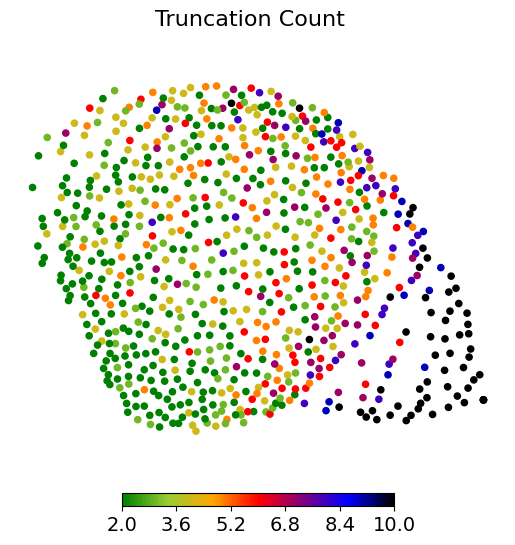

In [453]:
experiment7.print_map_2d_colored_by_feature(feature_id='trunc_count', title = 'Truncation Count', saveas='trunc_count_map.pdf')

In [454]:
experiment8 = mapof.prepare_online_marriages_experiment()

In [455]:
experiment8.add_family(culture_id = 'reverse_euclidean', size = 148, label = 'Semi-Euclidean', color = 'red')

experiment8.add_family(culture_id = 'norm-mallows', size = 136, label="Mallows-Identical", color = 'blue')

experiment8.add_family(culture_id = 'asymmetric', size = 128, label = 'Mallows-MD', color = 'green')

experiment8.add_family(culture_id = 'symmetric', size = 100, label = 'Mallows-MA', color = 'orange')

experiment8.add_family(culture_id = 'mallows_euclidean', size = 120, label = 'Mallows-Euclidean', color = 'purple')

experiment8.add_family(culture_id = 'expectation', size = 127, label = 'Expectation-Euclidean', color = 'brown')

['expectation_10_0',
 'expectation_10_1',
 'expectation_10_2',
 'expectation_10_3',
 'expectation_10_4',
 'expectation_10_5',
 'expectation_10_6',
 'expectation_10_7',
 'expectation_10_8',
 'expectation_10_9',
 'expectation_10_10',
 'expectation_10_11',
 'expectation_10_12',
 'expectation_10_13',
 'expectation_10_14',
 'expectation_10_15',
 'expectation_10_16',
 'expectation_10_17',
 'expectation_10_18',
 'expectation_10_19',
 'expectation_10_20',
 'expectation_10_21',
 'expectation_10_22',
 'expectation_10_23',
 'expectation_10_24',
 'expectation_10_25',
 'expectation_10_26',
 'expectation_10_27',
 'expectation_10_28',
 'expectation_10_29',
 'expectation_10_30',
 'expectation_10_31',
 'expectation_10_32',
 'expectation_10_33',
 'expectation_10_34',
 'expectation_10_35',
 'expectation_10_36',
 'expectation_10_37',
 'expectation_10_38',
 'expectation_10_39',
 'expectation_10_40',
 'expectation_10_41',
 'expectation_10_42',
 'expectation_10_43',
 'expectation_10_44',
 'expectation_10_45'

In [456]:
reverse_euc_counter = 0
mallows_counter = 0
mallows_MD_counter = 0
mallows_MA_counter = 0
mallows_euclidean_counter = 0
expectations_euclidean_counter = 0

for key in experiment8.instances.keys():
    if key.startswith('reverse_euclidean'):
        experiment8.instances[key].votes = future_votes_rev_euclidean[reverse_euc_counter]
        #experiment4.instances[key].features['self_freq_instance'] = rev_euclid_feature[reverse_euc_counter]
        reverse_euc_counter += 8
    elif key.startswith('norm-mallows_'):
        experiment8.instances[key].votes = future_votes_mallows[mallows_counter]
        #experiment4.instances[key].features['self_freq_instance'] = mallows_feature[mallows_counter]
        mallows_counter += 7
    elif key.startswith('asymmetric_'):
        experiment8.instances[key].votes = future_votes_mallows_MD[mallows_MD_counter]
        #experiment4.instances[key].features['self_freq_instance'] = mallows_MD_feature[mallows_MD_counter]
        mallows_MD_counter += 27
    elif key.startswith('symmetric_'):
        experiment8.instances[key].votes = future_votes_mallows_MA[mallows_MA_counter]
        #experiment4.instances[key].features['self_freq_instance'] = mallows_MA_feature[mallows_MA_counter]
        mallows_MA_counter += 19
    elif key.startswith('mallows_euclidean_'):
        experiment8.instances[key].votes = future_votes_mallows_euclidean[mallows_euclidean_counter]
        #experiment4.instances[key].features['self_freq_instance'] = mallows_euclidean_feature[mallows_euclidean_counter]
        mallows_euclidean_counter += 14
    elif key.startswith('expectation_'):
        experiment8.instances[key].votes = future_votes_expectations_euclidean[expectations_euclidean_counter]
        #experiment4.instances[key].features['self_freq_instance'] = expectations_euclidean_feature[expectations_euclidean_counter]
        expectations_euclidean_counter += 6

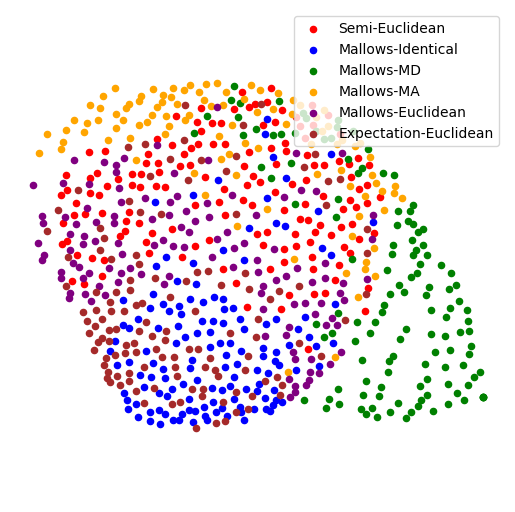

In [457]:
experiment8.compute_distances(distance_id='l1-mutual_attraction')
experiment8.embed_2d(embedding_id='kk')
experiment8.print_map_2d()

In [476]:
reverse_euclid = pandas.read_csv('reverse_euclidean_gain_egal.csv')
mallows = pandas.read_csv('mallows_gain_egal.csv')
mallows_MD = pandas.read_csv('mallows_MD_gain_egal.csv')
mallows_MA = pandas.read_csv('mallows_MA_gain_egal.csv')
mallows_euclidean = pandas.read_csv('mallows_euclidean_gain_egal.csv')
expectations_euclidean = pandas.read_csv('expectations_euclidean_gain.csv')

In [477]:
future_votes_rev_euclidean = reverse_euclid['preferences'].apply(literal_eval)
rev_euclid_feature = reverse_euclid['trunc_egal']

future_votes_mallows = mallows['preferences'].apply(literal_eval)
mallows_feature = mallows['trunc_egal']

future_votes_mallows_MD = mallows_MD['preferences'].apply(literal_eval)
mallows_MD_feature = mallows_MD['trunc_egal']

future_votes_mallows_MA = mallows_MA['preferences'].apply(literal_eval)
mallows_MA_feature = mallows_MA['trunc_egal']

future_votes_mallows_euclidean = mallows_euclidean['preferences'].apply(literal_eval)
mallows_euclidean_feature = mallows_euclidean['trunc_egal']

future_votes_expectations_euclidean = expectations_euclidean['preferences'].apply(literal_eval)
expectations_euclidean_feature = expectations_euclidean['trunc_egal']

In [478]:
rev_euclid_feature, future_votes_rev_euclidean = zip(*[
    (fval, fv)
    for fval, fv in zip(rev_euclid_feature, future_votes_rev_euclidean)
    if fval != 0 #to get back to other map that includes 0s, comment out this line for all 6 cultures
])
rev_euclid_feature = list(rev_euclid_feature)
future_votes_rev_euclidean = list(future_votes_rev_euclidean)

mallows_feature, future_votes_mallows = zip(*[
    (fval, fv)
    for fval, fv in zip(mallows_feature, future_votes_mallows)
    if fval != 0
])
mallows_feature = list(mallows_feature)
future_votes_mallows = list(future_votes_mallows)

mallows_MD_feature, future_votes_mallows_MD = zip(*[
    (fval, fv)
    for fval, fv in zip(mallows_MD_feature, future_votes_mallows_MD)
    if fval != 0
])
mallows_MD_feature = list(mallows_MD_feature)
future_votes_mallows_MD = list(future_votes_mallows_MD)

mallows_MA_feature, future_votes_mallows_MA = zip(*[
    (fval, fv)
    for fval, fv in zip(mallows_MA_feature, future_votes_mallows_MA)
    if fval != 0
])
mallows_MA_feature = list(mallows_MA_feature)
future_votes_mallows_MA = list(future_votes_mallows_MA)

mallows_euclidean_feature, future_votes_mallows_euclidean = zip(*[
    (fval, fv)
    for fval, fv in zip(mallows_euclidean_feature, future_votes_mallows_euclidean)
    if fval != 0
])
mallows_euclidean_feature = list(mallows_euclidean_feature)
future_votes_mallows_euclidean = list(future_votes_mallows_euclidean)

expectations_euclidean_feature, future_votes_expectations_euclidean = zip(*[
    (fval, fv)
    for fval, fv in zip(expectations_euclidean_feature, future_votes_expectations_euclidean)
    if fval != 0
])
expectations_euclidean_feature = list(expectations_euclidean_feature)
future_votes_expectations_euclidean = list(future_votes_expectations_euclidean)

In [479]:
for i in range(len(future_votes_rev_euclidean)):
        future_votes_rev_euclidean[i][0] = np.array(future_votes_rev_euclidean[i][0]) -1
        future_votes_rev_euclidean[i][1] =  np.array(future_votes_rev_euclidean[i][1]) -1
for i in range(len(future_votes_mallows)):
        future_votes_mallows[i][0] = np.array(future_votes_mallows[i][0]) -1
        future_votes_mallows[i][1] =  np.array(future_votes_mallows[i][1]) -1

for i in range(len(future_votes_mallows_MD)):
        future_votes_mallows_MD[i][0] = np.array(future_votes_mallows_MD[i][0]) -1
        future_votes_mallows_MD[i][1] =  np.array(future_votes_mallows_MD[i][1]) -1

for i in range(len(future_votes_mallows_MA)):
        future_votes_mallows_MA[i][0] = np.array(future_votes_mallows_MA[i][0]) -1
        future_votes_mallows_MA[i][1] =  np.array(future_votes_mallows_MA[i][1]) -1

for i in range(len(future_votes_mallows_euclidean)):
        future_votes_mallows_euclidean[i][0] = np.array(future_votes_mallows_euclidean[i][0]) -1
        future_votes_mallows_euclidean[i][1] =  np.array(future_votes_mallows_euclidean[i][1]) -1

for i in range(len(future_votes_expectations_euclidean)):
        future_votes_expectations_euclidean[i][0] = np.array(future_votes_expectations_euclidean[i][0]) -1
        future_votes_expectations_euclidean[i][1] =  np.array(future_votes_expectations_euclidean[i][1]) -1

In [480]:
len(future_votes_rev_euclidean), len(future_votes_mallows), len(future_votes_mallows_MD), len(future_votes_mallows_MA), len(future_votes_mallows_euclidean), len(future_votes_expectations_euclidean)

(1184, 953, 3456, 1902, 1686, 764)

In [481]:
future_votes_mallows = future_votes_mallows[0:952]
future_votes_mallow_MA = future_votes_mallows_MA[0:1900]
future_votes_mallows_euclidean = future_votes_mallows_euclidean[0:1680]
future_votes_expectations_euclidean = future_votes_expectations_euclidean[0:762]

In [482]:
experiment9 = mapof.prepare_online_marriages_experiment()

In [483]:
experiment9.add_family(culture_id = 'reverse_euclidean', size = 148, label = 'Semi-Euclidean')

experiment9.add_family(culture_id = 'norm-mallows', size = 136, label="Mallows-Identical")

experiment9.add_family(culture_id = 'asymmetric', size = 128, label = 'Mallows-MD')

experiment9.add_family(culture_id = 'symmetric', size = 100, label = 'Mallows-MA')

experiment9.add_family(culture_id = 'mallows_euclidean', size = 120, label = 'Mallows-Euclidean')

experiment9.add_family(culture_id = 'expectation', size = 127, label = 'Expectation-Euclidean')

['expectation_10_0',
 'expectation_10_1',
 'expectation_10_2',
 'expectation_10_3',
 'expectation_10_4',
 'expectation_10_5',
 'expectation_10_6',
 'expectation_10_7',
 'expectation_10_8',
 'expectation_10_9',
 'expectation_10_10',
 'expectation_10_11',
 'expectation_10_12',
 'expectation_10_13',
 'expectation_10_14',
 'expectation_10_15',
 'expectation_10_16',
 'expectation_10_17',
 'expectation_10_18',
 'expectation_10_19',
 'expectation_10_20',
 'expectation_10_21',
 'expectation_10_22',
 'expectation_10_23',
 'expectation_10_24',
 'expectation_10_25',
 'expectation_10_26',
 'expectation_10_27',
 'expectation_10_28',
 'expectation_10_29',
 'expectation_10_30',
 'expectation_10_31',
 'expectation_10_32',
 'expectation_10_33',
 'expectation_10_34',
 'expectation_10_35',
 'expectation_10_36',
 'expectation_10_37',
 'expectation_10_38',
 'expectation_10_39',
 'expectation_10_40',
 'expectation_10_41',
 'expectation_10_42',
 'expectation_10_43',
 'expectation_10_44',
 'expectation_10_45'

In [485]:
reverse_euc_counter = 0
mallows_counter = 0
mallows_MD_counter = 0
mallows_MA_counter = 0
mallows_euclidean_counter = 0
expectations_euclidean_counter = 0

for key in experiment9.instances.keys():
    if key.startswith('reverse_euclidean'):
        experiment9.instances[key].votes = future_votes_rev_euclidean[reverse_euc_counter]
        experiment9.instances[key].features['trunc_egal'] = rev_euclid_feature[reverse_euc_counter]
        reverse_euc_counter += 8
    elif key.startswith('norm-mallows_'):
        experiment9.instances[key].votes = future_votes_mallows[mallows_counter]
        experiment9.instances[key].features['trunc_egal'] = mallows_feature[mallows_counter]
        mallows_counter += 7
    elif key.startswith('asymmetric_'):
        experiment9.instances[key].votes = future_votes_mallows_MD[mallows_MD_counter]
        experiment9.instances[key].features['trunc_egal'] = mallows_MD_feature[mallows_MD_counter]
        mallows_MD_counter += 27
    elif key.startswith('symmetric_'):
        experiment9.instances[key].votes = future_votes_mallows_MA[mallows_MA_counter]
        experiment9.instances[key].features['trunc_egal'] = mallows_MA_feature[mallows_MA_counter]
        mallows_MA_counter += 19
    elif key.startswith('mallows_euclidean_'):
        experiment9.instances[key].votes = future_votes_mallows_euclidean[mallows_euclidean_counter]
        experiment9.instances[key].features['trunc_egal'] = mallows_euclidean_feature[mallows_euclidean_counter]
        mallows_euclidean_counter += 14
    elif key.startswith('expectation_'):
        experiment9.instances[key].votes = future_votes_expectations_euclidean[expectations_euclidean_counter]
        experiment9.instances[key].features['trunc_egal'] = expectations_euclidean_feature[expectations_euclidean_counter]
        expectations_euclidean_counter += 6

In [486]:
experiment9.compute_distances(distance_id='l1-mutual_attraction')
experiment9.embed_2d(embedding_id='kk')

In [487]:
experiment9.features['trunc_egal'] = {'value':{}}

In [488]:
for key in experiment9.instances.keys():
    experiment9.features['trunc_egal']['value'][key] = (experiment9.instances[key].features['trunc_egal'])

In [489]:
experiment9.experiment_id = 'trunc_egal_gain'

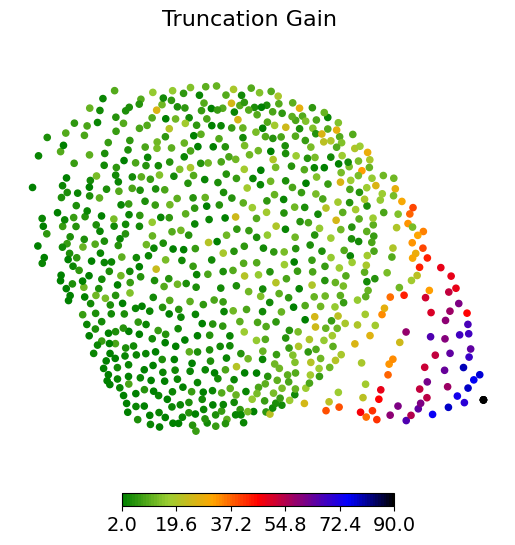

In [490]:
experiment9.print_map_2d_colored_by_feature(feature_id='trunc_egal', title = 'Truncation Gain', saveas='trunc_egal_gain_map.pdf')

In [491]:
experiment10 = mapof.prepare_online_marriages_experiment()

In [492]:
experiment10.add_family(culture_id = 'reverse_euclidean', size = 148, label = 'Semi-Euclidean', color = 'red')

experiment10.add_family(culture_id = 'norm-mallows', size = 136, label="Mallows-Identical", color = 'blue')

experiment10.add_family(culture_id = 'asymmetric', size = 128, label = 'Mallows-MD', color = 'green')

experiment10.add_family(culture_id = 'symmetric', size = 100, label = 'Mallows-MA', color = 'orange')

experiment10.add_family(culture_id = 'mallows_euclidean', size = 120, label = 'Mallows-Euclidean', color = 'purple')

experiment10.add_family(culture_id = 'expectation', size = 127, label = 'Expectation-Euclidean', color = 'brown')

['expectation_10_0',
 'expectation_10_1',
 'expectation_10_2',
 'expectation_10_3',
 'expectation_10_4',
 'expectation_10_5',
 'expectation_10_6',
 'expectation_10_7',
 'expectation_10_8',
 'expectation_10_9',
 'expectation_10_10',
 'expectation_10_11',
 'expectation_10_12',
 'expectation_10_13',
 'expectation_10_14',
 'expectation_10_15',
 'expectation_10_16',
 'expectation_10_17',
 'expectation_10_18',
 'expectation_10_19',
 'expectation_10_20',
 'expectation_10_21',
 'expectation_10_22',
 'expectation_10_23',
 'expectation_10_24',
 'expectation_10_25',
 'expectation_10_26',
 'expectation_10_27',
 'expectation_10_28',
 'expectation_10_29',
 'expectation_10_30',
 'expectation_10_31',
 'expectation_10_32',
 'expectation_10_33',
 'expectation_10_34',
 'expectation_10_35',
 'expectation_10_36',
 'expectation_10_37',
 'expectation_10_38',
 'expectation_10_39',
 'expectation_10_40',
 'expectation_10_41',
 'expectation_10_42',
 'expectation_10_43',
 'expectation_10_44',
 'expectation_10_45'

In [493]:
reverse_euc_counter = 0
mallows_counter = 0
mallows_MD_counter = 0
mallows_MA_counter = 0
mallows_euclidean_counter = 0
expectations_euclidean_counter = 0

for key in experiment10.instances.keys():
    if key.startswith('reverse_euclidean'):
        experiment10.instances[key].votes = future_votes_rev_euclidean[reverse_euc_counter]
        #experiment4.instances[key].features['self_freq_instance'] = rev_euclid_feature[reverse_euc_counter]
        reverse_euc_counter += 8
    elif key.startswith('norm-mallows_'):
        experiment10.instances[key].votes = future_votes_mallows[mallows_counter]
        #experiment4.instances[key].features['self_freq_instance'] = mallows_feature[mallows_counter]
        mallows_counter += 7
    elif key.startswith('asymmetric_'):
        experiment10.instances[key].votes = future_votes_mallows_MD[mallows_MD_counter]
        #experiment4.instances[key].features['self_freq_instance'] = mallows_MD_feature[mallows_MD_counter]
        mallows_MD_counter += 27
    elif key.startswith('symmetric_'):
        experiment10.instances[key].votes = future_votes_mallows_MA[mallows_MA_counter]
        #experiment4.instances[key].features['self_freq_instance'] = mallows_MA_feature[mallows_MA_counter]
        mallows_MA_counter += 19
    elif key.startswith('mallows_euclidean_'):
        experiment10.instances[key].votes = future_votes_mallows_euclidean[mallows_euclidean_counter]
        #experiment4.instances[key].features['self_freq_instance'] = mallows_euclidean_feature[mallows_euclidean_counter]
        mallows_euclidean_counter += 14
    elif key.startswith('expectation_'):
        experiment10.instances[key].votes = future_votes_expectations_euclidean[expectations_euclidean_counter]
        #experiment4.instances[key].features['self_freq_instance'] = expectations_euclidean_feature[expectations_euclidean_counter]
        expectations_euclidean_counter += 6

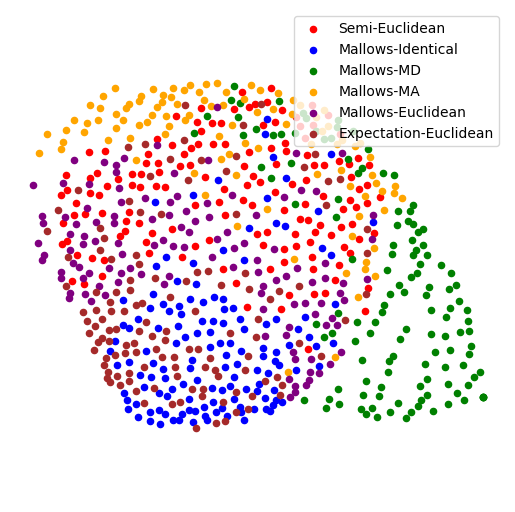

In [494]:
experiment10.compute_distances(distance_id='l1-mutual_attraction')
experiment10.embed_2d(embedding_id='kk')
experiment10.print_map_2d()